In [2]:
import requests
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import style

sns.set(rc = {'figure.figsize': (20, 20)})

%matplotlib inline

inner_merged_df = pd.read_csv('vehicles.csv',index_col=0)


In [3]:
# Performing exploratory data analysis
# Display the first few rows of the DataFrame
inner_merged_df.head()

,vin,manufacturer,year,color,body_type,engine_type,transmission,fuel_type,seating_capacity,kilometers_driven,vehicle_condition_status,selling_price,owner_name,owner_profession,owner_age,owner_district,proposed_purchase_price,purchase_date
0,KNEQQMPI59JQMQFUS,Volkswagen,2023,metallic_black,Truck,electric,manual,gasoline,6,19.84,inactive,5980.16,KARABO Nadege,librarian,49,east_nyagatare,6705.76,2024-01-24
1,Y06254A9NYNT183XI,Audi,2021,matte_black,Convertible,diesel,automatic,hybrid,10,19.83,active,8778.19,UWASE TETA Paola,economist,84,south_kamonyi,10008.46,2016-07-21
2,U8J8TBA70SBBGVXT1,Nissan,2020,metallic_silver,Wagon,petrol,manual,biodiesel,3,78.73,inactive,8921.27,IMANISINGIZWE KAMANA Adeodatus Clare,mechanic,38,kigali_gasabo,10219.33,2022-06-07
3,ZWEG0R44V9S72T8CO,Chevrolet,2012,gray,Van,petrol,automatic,ethanol,6,46.02,inactive,16953.98,IMANISHIMWE Emmanuel,hairdresser,33,west_rusizi,19288.22,2006-03-15
4,XRNFVKZUXQ4WJHJTK,Nissan,2009,purple,Hatchback,petrol,manual,gasoline,10,247.39,active,21727.87,IRASUBIZA Divine,baker,86,east_rwamagana,22848.39,2021-06-14


In [4]:
# Summary statistics for numerical columns
inner_merged_df.describe()


,year,seating_capacity,kilometers_driven,selling_price,owner_age,proposed_purchase_price
count,499746.000000,499746.000000,499746.000000,499746.000000,499746.000000,499746.000000
mean,2011.995770,5.999532,120.362064,17658.561496,59.013005,19425.720447
std,7.204957,2.583512,108.449333,7580.377670,23.933346,8358.384150
min,2000.000000,2.000000,0.000000,4500.000000,18.000000,4725.020000
25%,2006.000000,4.000000,30.730000,10965.082500,38.000000,12256.542500
50%,2012.000000,6.000000,89.290000,17522.420000,59.000000,19302.405000
75%,2018.000000,8.000000,185.150000,23976.257500,80.000000,26363.872500
max,2024.000000,10.000000,479.980000,31899.990000,100.000000,53801.410000


In [5]:
# Get the shape of the DataFrame
print(f"Shape of the DataFrame: \n{inner_merged_df.shape}")


Shape of the DataFrame: 
(499746, 18)


In [6]:
# Display unique values for categorical columns
categorical_columns = inner_merged_df.select_dtypes(include=["object"]).columns
for col in categorical_columns:
    unique_values = inner_merged_df[col].unique()
    print(f"{col}: {len(unique_values)} unique values")


vin: 499746 unique values
manufacturer: 10 unique values
color: 23 unique values
body_type: 8 unique values
engine_type: 3 unique values
transmission: 2 unique values
fuel_type: 7 unique values
vehicle_condition_status: 2 unique values
owner_name: 139 unique values
owner_profession: 89 unique values
owner_district: 30 unique values
purchase_date: 8400 unique values


In [7]:
print('\n Value counts')

print(inner_merged_df['manufacturer'].value_counts())

print(inner_merged_df['manufacturer'].nunique())

for col in inner_merged_df.columns:
    print(inner_merged_df[col].value_counts())


 Value counts
manufacturer
Audi          50272
Honda         50244
Chevrolet     50138
Ford          50138
Mercedes      49925
Nissan        49880
Hyundai       49876
BMW           49817
Toyota        49755
Volkswagen    49701
Name: count, dtype: int64
10
vin
KNEQQMPI59JQMQFUS    1
LI0OA4X2YTWYSXGEF    1
CRZTNT7KHWZ0JTBP3    1
B24LVZCB1VAPC79I9    1
IZLZMOEAFFLEDCJ0B    1
                    ..
FBDKL10ZNKCADT0OV    1
CLQUVCHMXOJBZ62EZ    1
E1QKMHWMP59JP8443    1
X40ZXPHUU6469XA8I    1
K1YXRQOWFRG2M351R    1
Name: count, Length: 499746, dtype: int64
manufacturer
Audi          50272
Honda         50244
Chevrolet     50138
Ford          50138
Mercedes      49925
Nissan        49880
Hyundai       49876
BMW           49817
Toyota        49755
Volkswagen    49701
Name: count, dtype: int64
year
2016    20365
2008    20285
2018    20101
2001    20094
2014    20082
2017    20055
2015    20052
2023    20043
2006    20015
2010    20013
2003    19990
2002    19989
2011    19979
2004    19974
2013

In [8]:
# Display the column names
print(f"Column names: \n{inner_merged_df.columns.to_list()}")


Column names: 
['vin', 'manufacturer', 'year', 'color', 'body_type', 'engine_type', 'transmission', 'fuel_type', 'seating_capacity', 'kilometers_driven', 'vehicle_condition_status', 'selling_price', 'owner_name', 'owner_profession', 'owner_age', 'owner_district', 'proposed_purchase_price', 'purchase_date']


In [9]:
# Display the data types of each column
inner_merged_df.dtypes


vin                          object
manufacturer                 object
year                          int64
color                        object
body_type                    object
engine_type                  object
transmission                 object
fuel_type                    object
seating_capacity              int64
kilometers_driven           float64
vehicle_condition_status     object
selling_price               float64
owner_name                   object
owner_profession             object
owner_age                     int64
owner_district               object
proposed_purchase_price     float64
purchase_date                object
dtype: object

In [10]:
inner_merged_df[["owner_name", "vin"]]


,owner_name,vin
0,KARABO Nadege,KNEQQMPI59JQMQFUS
1,UWASE TETA Paola,Y06254A9NYNT183XI
2,IMANISINGIZWE KAMANA Adeodatus Clare,U8J8TBA70SBBGVXT1
3,IMANISHIMWE Emmanuel,ZWEG0R44V9S72T8CO
4,IRASUBIZA Divine,XRNFVKZUXQ4WJHJTK
...,...,...
499741,NDAYAMBAJE Patrick,CQKFTDB3PATH31NRK
499742,ISHIMWE ARLENE,XV0S95MH6Q96UT9V1
499743,ISHIMWE PRINCE ARNAUD,FU6BSORX4Z369WJTM
499744,GISINGIZO Gloria,OQBLQCK353L8VXN5I


In [11]:
# Data Cleaning and Preprocessing
inner_merged_df.drop(["owner_name",'vin'], axis=1, inplace=True)
# Check for missing values 
print(inner_merged_df.isnull().sum())
# Forward fill for simplicity; you can choose other methods as needed
#inner_merged_df.ffill(inplace=True)


manufacturer                0
year                        0
color                       0
body_type                   0
engine_type                 0
transmission                0
fuel_type                   0
seating_capacity            0
kilometers_driven           0
vehicle_condition_status    0
selling_price               0
owner_profession            0
owner_age                   0
owner_district              0
proposed_purchase_price     0
purchase_date               0
dtype: int64


In [12]:
inner_merged_df.dtypes

manufacturer                 object
year                          int64
color                        object
body_type                    object
engine_type                  object
transmission                 object
fuel_type                    object
seating_capacity              int64
kilometers_driven           float64
vehicle_condition_status     object
selling_price               float64
owner_profession             object
owner_age                     int64
owner_district               object
proposed_purchase_price     float64
purchase_date                object
dtype: object

In [13]:
    # Convert Data Types
    """errors parameter can contain {
    raise: (default) raises an error for invalid parsing.
    coerce: converts invalid parsing to NaN
    ignore: returns the original data without any changes
    } """
    
    inner_merged_df['selling_price'] = inner_merged_df['selling_price'].astype(float)
    inner_merged_df["proposed_purchase_price "] = pd.to_numeric(inner_merged_df["proposed_purchase_price"], errors="coerce", downcast="float")
    inner_merged_df["purchase_date"] = pd.to_datetime(inner_merged_df["purchase_date"], errors="coerce")
    inner_merged_df.dtypes

manufacturer                        object
year                                 int64
color                               object
body_type                           object
engine_type                         object
transmission                        object
fuel_type                           object
seating_capacity                     int64
kilometers_driven                  float64
vehicle_condition_status            object
selling_price                      float64
owner_profession                    object
owner_age                            int64
owner_district                      object
proposed_purchase_price            float64
purchase_date               datetime64[ns]
proposed_purchase_price            float64
dtype: object

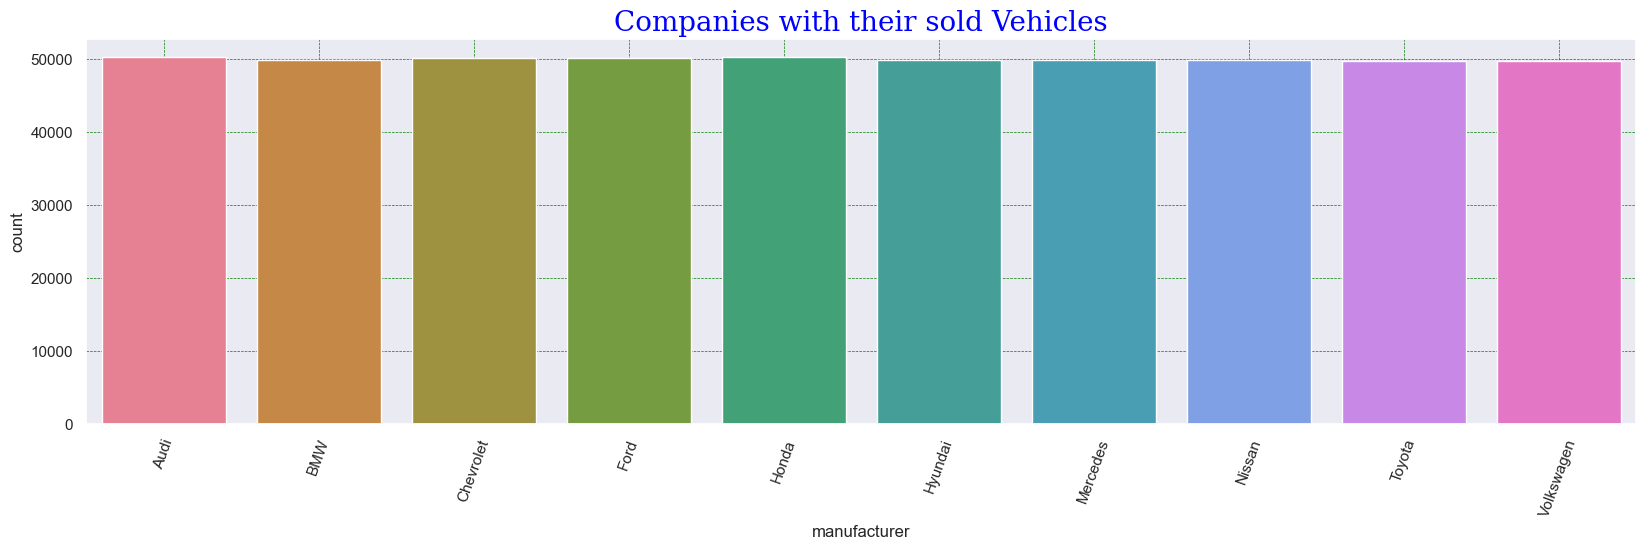

In [14]:
plt.figure(figsize = (20, 5))
sns.countplot(x='manufacturer', data=inner_merged_df.sort_values(by='manufacturer'), hue='manufacturer', palette='husl', legend=False)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Companies with their sold Vehicles", fontdict={"family": "serif", "color": "blue", "size": 20})
plt.xticks(rotation=70)  # Optional: Rotate x labels for better visibility
plt.show()

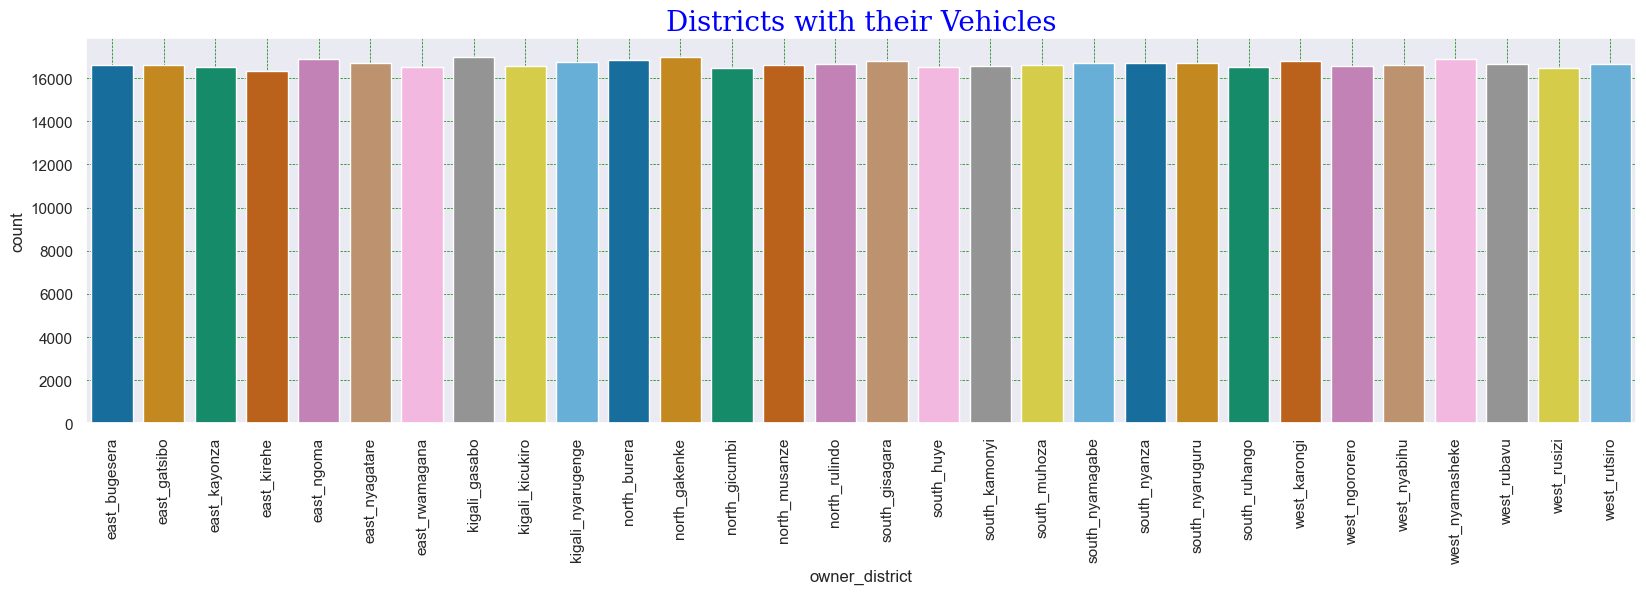

In [15]:
plt.figure(figsize = (20, 5))
sns.countplot(x='owner_district', data=inner_merged_df.sort_values(by='owner_district'), hue='owner_district', palette='colorblind', legend=False)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Districts with their Vehicles", fontdict={"family": "serif", "color": "blue", "size": 20})
plt.xticks(rotation=90)  # Optional: Rotate x labels for better visibility
plt.show()

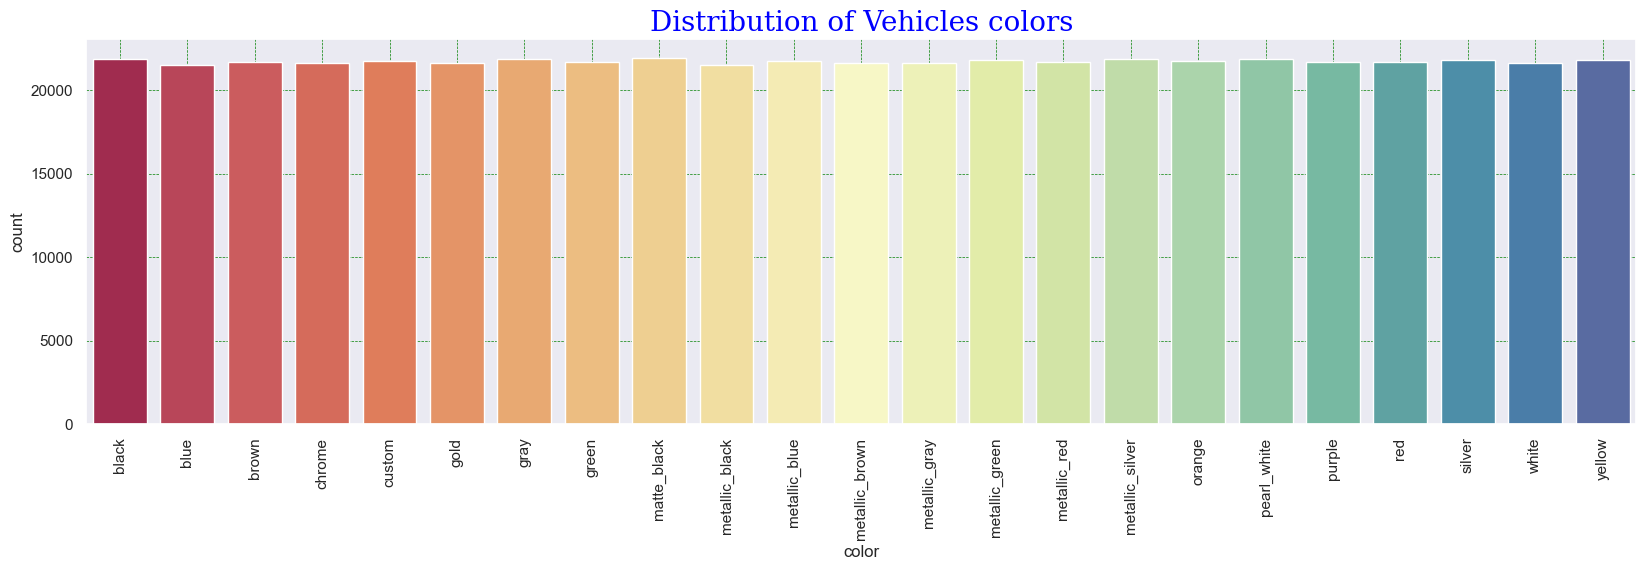

In [16]:
plt.figure(figsize = (20, 5))
sns.countplot(x='color', data=inner_merged_df.sort_values(by='color'), hue='color', palette='Spectral', legend=False)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Distribution of Vehicles colors", fontdict={"family": "serif", "color": "blue", "size": 20})
plt.xticks(rotation=90)  # Optional: Rotate x labels for better visibility
plt.show()

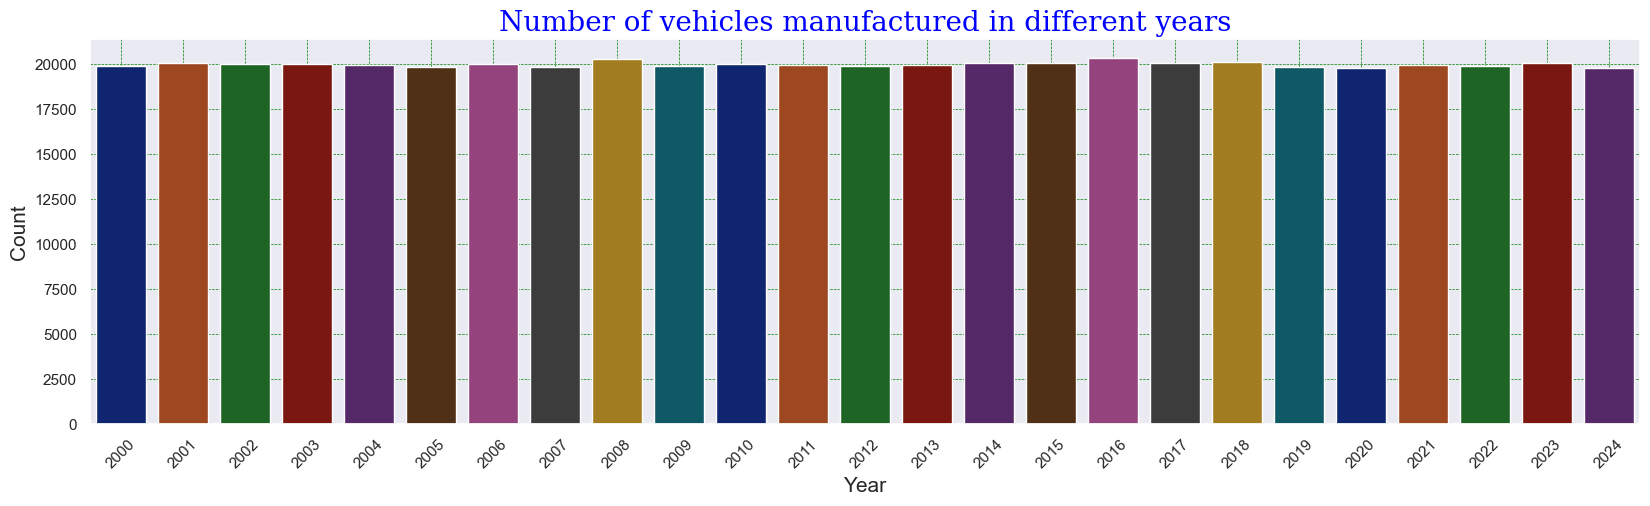

In [17]:
# Assuming 'car_data' is your DataFrame and 'Year' is the column to count
plt.figure(figsize=(20, 5))
sns.countplot(x='year', data=inner_merged_df, hue='year', palette='dark', legend=False)  # Use 'x' for the column
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Number of vehicles manufactured in different years", fontdict={"family": "serif", "color": "blue", "size": 20})
plt.xlabel("Year", fontsize=15)  # Optional: Label for the x-axis
plt.ylabel("Count", fontsize=15)  # Optional: Label for the y-axis
plt.xticks(rotation=45)  # Optional: Rotate x labels for better visibility
plt.show()

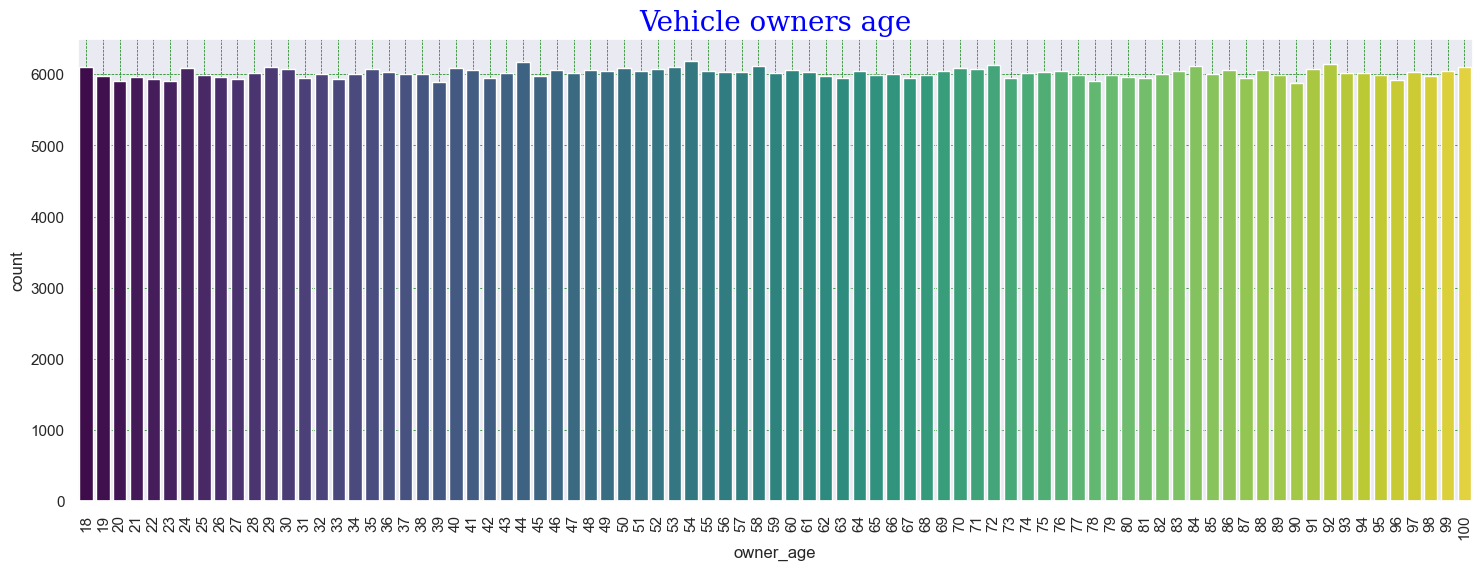

In [18]:
plt.figure(figsize=(18, 6))
sns.countplot(x='owner_age', data=inner_merged_df, hue='owner_age', palette='viridis', legend=False)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Vehicle owners age", fontdict={"family": "serif", "color": "blue", "size": 20})
plt.xticks(rotation=90)  # Optional: Rotate x labels for better visibility
plt.show()

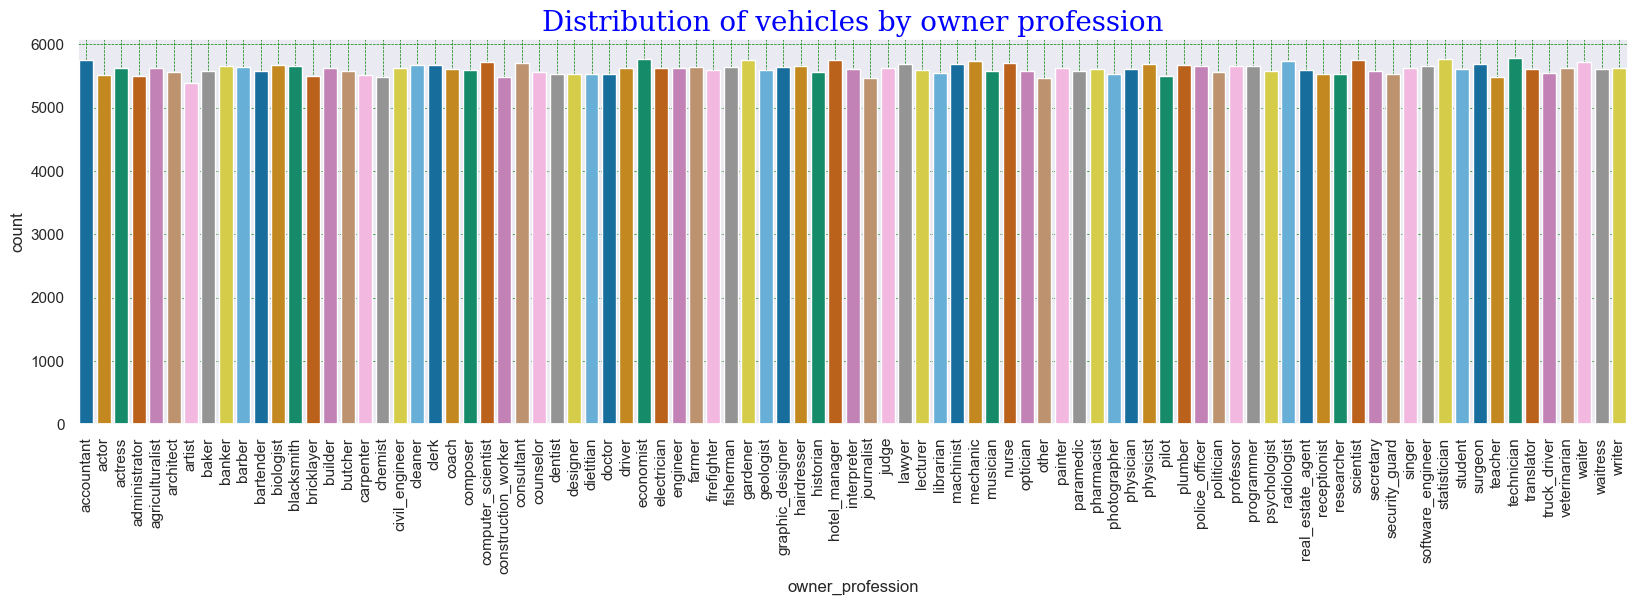

In [19]:
plt.figure(figsize = (20, 5))
sns.countplot(x='owner_profession', data=inner_merged_df.sort_values(by='owner_profession'), hue='owner_profession', palette='colorblind', legend=False)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Distribution of vehicles by owner profession", fontdict={"family": "serif", "color": "blue", "size": 20})
plt.xticks(rotation=90)  # Optional: Rotate x labels for better visibility
plt.show()

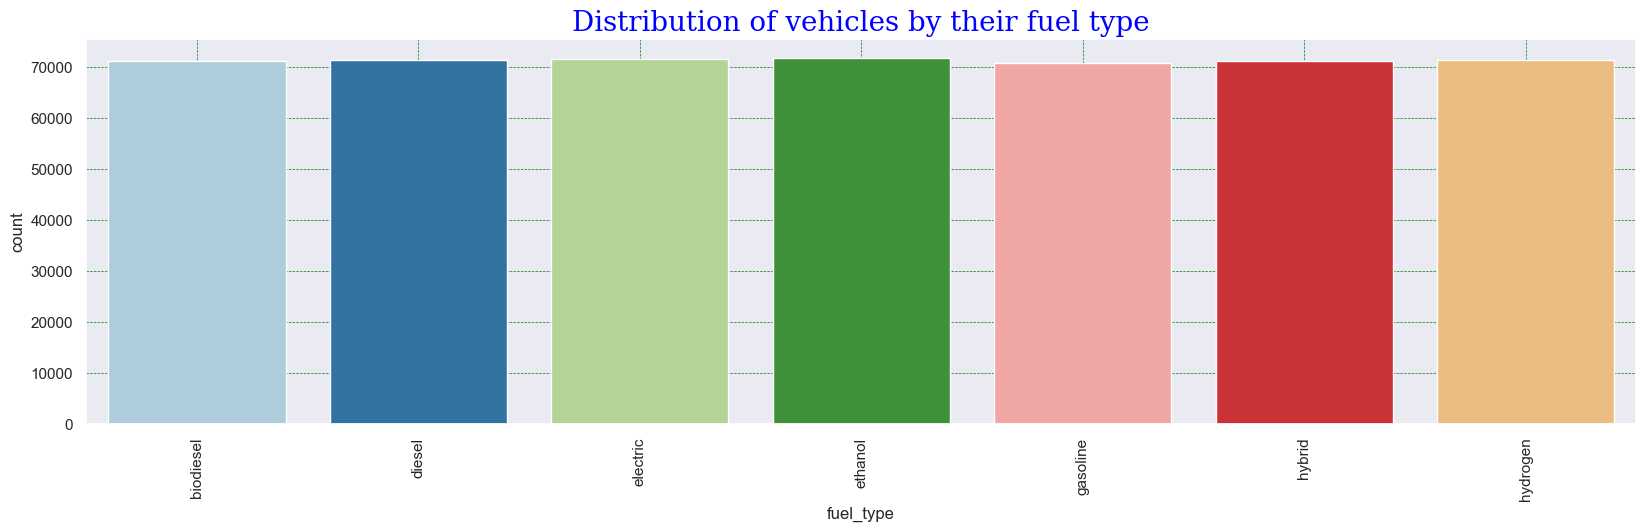

In [20]:
plt.figure(figsize = (20, 5))
sns.countplot(x='fuel_type', data=inner_merged_df.sort_values(by='fuel_type'), hue='fuel_type', palette='Paired', legend=False)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Distribution of vehicles by their fuel type", fontdict={"family": "serif", "color": "blue", "size": 20})
plt.xticks(rotation=90)  # Optional: Rotate x labels for better visibility
plt.show()

In [21]:
inner_merged_df.nunique()

manufacturer                    10
year                            25
color                           23
body_type                        8
engine_type                      3
transmission                     2
fuel_type                        7
seating_capacity                 9
kilometers_driven            44561
vehicle_condition_status         2
selling_price               356474
owner_profession                89
owner_age                       83
owner_district                  30
proposed_purchase_price     458928
purchase_date                 8400
proposed_purchase_price     458928
dtype: int64

In [22]:

print(inner_merged_df.groupby('manufacturer'))


In [23]:
grouped = inner_merged_df.groupby('manufacturer')
for name, group in grouped:
    print(f"Manufacturer: {name}")
    print(group)

Manufacturer: Audi
       manufacturer  year           color    body_type engine_type  \
1              Audi  2021     matte_black  Convertible      diesel   
8              Audi  2010     matte_black          SUV    electric   
10             Audi  2023           white        Sedan      diesel   
20             Audi  2018  metallic_black        Wagon    electric   
28             Audi  2012     pearl_white          Van      diesel   
...             ...   ...             ...          ...         ...   
499700         Audi  2002           green          SUV    electric   
499713         Audi  2007     matte_black        Wagon      diesel   
499714         Audi  2013  metallic_green        Truck      petrol   
499717         Audi  2005          silver        Wagon      diesel   
499725         Audi  2008           green  Convertible    electric   

       transmission fuel_type  seating_capacity  kilometers_driven  \
1         automatic    hybrid                10              19.83   


In [24]:
print(inner_merged_df.groupby('manufacturer').size())  # Count rows per group
result = inner_merged_df.groupby('manufacturer').mean(numeric_only=True)
print(result)
  # Mean of numeric columns


manufacturer
Audi          50272
BMW           49817
Chevrolet     50138
Ford          50138
Honda         50244
Hyundai       49876
Mercedes      49925
Nissan        49880
Toyota        49755
Volkswagen    49701
dtype: int64
                     year  seating_capacity  kilometers_driven  selling_price  \
manufacturer                                                                    
Audi          2011.964354          6.015297         120.969008   17683.165643   
BMW           2011.944959          6.024148         120.093470   17721.640969   
Chevrolet     2011.915673          6.006402         121.621644   17736.874981   
Ford          2012.034425          6.010770         119.820378   17617.172758   
Honda         2012.032621          5.980714         119.896146   17615.519562   
Hyundai       2012.026907          5.988351         119.576242   17627.392163   
Mercedes      2011.975383          5.987802         120.327167   17670.750838   
Nissan        2012.029451          5.986407  

In [25]:
grouped = inner_merged_df.groupby('manufacturer')
print(grouped.get_group('Audi'))  # Replace 'Toyota' with a valid group key


       manufacturer  year           color    body_type engine_type  \
1              Audi  2021     matte_black  Convertible      diesel   
8              Audi  2010     matte_black          SUV    electric   
10             Audi  2023           white        Sedan      diesel   
20             Audi  2018  metallic_black        Wagon    electric   
28             Audi  2012     pearl_white          Van      diesel   
...             ...   ...             ...          ...         ...   
499700         Audi  2002           green          SUV    electric   
499713         Audi  2007     matte_black        Wagon      diesel   
499714         Audi  2013  metallic_green        Truck      petrol   
499717         Audi  2005          silver        Wagon      diesel   
499725         Audi  2008           green  Convertible    electric   

       transmission fuel_type  seating_capacity  kilometers_driven  \
1         automatic    hybrid                10              19.83   
8         automatic

In [26]:
plt.figure(figsize = (15, 4))
inner_merged_df.groupby('manufacturer')['purchase_price'].sum().plot(kind = 'pie', autopct='%1.1f%%', startangle=90, legend=False)
plt.title("The income in different manufacturers", fontsize = 20)
plt.show()

KeyError: 'Column not found: purchase_price'

In [ ]:
plt.figure(figsize=(20, 4))
earned_by_manufacturer = inner_merged_df.groupby('manufacturer')['proposed_purchase_price'].sum().sort_values(ascending = True).plot(kind='barh', color='g')
plt.title("Money earned from vehicle by manufacturer type", fontsize=20)
plt.xlabel("Manufacturer", fontsize=15)
plt.ylabel("Purchase Price", fontsize=15)
plt.xticks(rotation=45)  # Rotate x-tick labels for better visibility
plt.grid(color="green", linestyle=":", linewidth=0.5)
plt.show()

In [ ]:
plt.figure(figsize=(20, 2))
earned_by_manufacturer = inner_merged_df.groupby('transmission')['purchase_price'].sum().plot(kind = 'barh', color = 'olivedrab')
plt.title("Money earned from vehicle by transmission type", fontsize=20)
plt.xlabel("Transmission type", fontsize=15)
plt.ylabel("Purchase Price", fontsize=15)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.show()

In [ ]:
plt.figure(figsize=(20, 3))
# Create scatter plot for selling_price
sns.scatterplot(x='selling_price', y='purchase_price', data=inner_merged_df, color='r', label='Selling Price', alpha=0.6)
# Create scatter plot for purchase_price
sns.scatterplot(x='purchase_price', y='selling_price', data=inner_merged_df, color='b', label='Purchase Price', alpha=0.6)
plt.title("Scatter Plot between Selling Price and Purchase Price", fontsize=20)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.xlabel("Price", fontsize=15)
plt.ylabel("Price", fontsize=15)
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(20, 3))
# Create the scatter plot for selling_price vs. purchase_price
sns.scatterplot(x='selling_price', y='purchase_price', data=inner_merged_df, color='b', alpha=0.6)
plt.title("Scatter Plot between Selling Price and Purchase Price", fontsize=20)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.xlabel("Selling Price", fontsize=15)
plt.ylabel("Purchase Price", fontsize=15)
plt.show()

In [ ]:
plt.figure(figsize = (20, 3))
numeric_columns = ['owner_age', 'selling_price', 'purchase_price', 'year', 'kilometers_driven']
heatmap_data = inner_merged_df[numeric_columns].corr()l
sns.heatmap(heatmap_data, cmap = 'BuPu', annot = True)
plt.show()

In [ ]:
print('Correlation between selling_price and kilometers_driven:', inner_merged_df['selling_price'].corr(inner_merged_df['kilometers_driven']))

In [ ]:
plt.figure(figsize = (20, 3))
sns.boxplot(data = inner_merged_df[['selling_price', 'purchase_price']], palette = 'Accent')
plt.title("Boxplot of selling_price and purchase_price", fontsize = 15)
plt.show()

In [ ]:
# Return all outliers (greater than 1500 or less than 0)
inner_merged_df[inner_merged_df['selling_price'] > 1500]

In [ ]:
# Remove outliers from the original DataFrame
inner_merged_df = inner_merged_df[inner_merged_df['selling_price'] < 1500]

In [ ]:
purchase_price_sum = inner_merged_df.groupby('manufacturer')['purchase_price'].sum()
plt.figure(figsize=(20, 3))
plt.bar(purchase_price_sum.index, purchase_price_sum.values, color=sns.color_palette("colorblind", len(purchase_price_sum)))
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Total Purchase Price by Manufacturer", fontsize=20)
plt.xlabel("Manufacturer", fontsize=15)
plt.ylabel("Total Purchase Price", fontsize=15)
plt.show()

In [ ]:

purchase_price_sum = inner_merged_df.groupby('body_type')['purchase_price'].sum()
plt.figure(figsize=(20, 3))
plt.bar(purchase_price_sum.index, purchase_price_sum.values, color=sns.color_palette("colorblind", len(purchase_price_sum)))
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Total Purchase Price by body_type", fontsize=20)
plt.xlabel("Body type", fontsize=15)
plt.ylabel("Total Purchase Price", fontsize=15)
plt.show()


In [ ]:

purchase_price_sum = inner_merged_df.groupby('engine_type')['purchase_price'].sum()
plt.figure(figsize=(20, 3))
plt.barh(purchase_price_sum.index, purchase_price_sum.values, color=sns.color_palette("husl", len(purchase_price_sum)))
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Total Purchase Price by engine_type", fontsize=20)
plt.ylabel("Engine type", fontsize=15)
plt.xlabel("Total Purchase Price", fontsize=15)
plt.show()


In [ ]:

purchase_price_sum = inner_merged_df.groupby('fuel_type')['purchase_price'].sum()
plt.figure(figsize=(20, 3))
plt.bar(purchase_price_sum.index, purchase_price_sum.values, color=sns.color_palette("husl", len(purchase_price_sum)))
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Total Purchase Price by fuel_type", fontsize=20)
plt.xlabel("Fuel type", fontsize=15)
plt.ylabel("Total Purchase Price", fontsize=15)
plt.xticks(rotation=90)  # Rotate x labels for better readability
plt.show()

In [ ]:

purchase_price_sum = inner_merged_df.groupby('owner_district')['purchase_price'].sum()
plt.figure(figsize=(20, 3))
plt.bar(purchase_price_sum.index, purchase_price_sum.values, color=sns.color_palette("husl", len(purchase_price_sum)))
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Total Purchase Price by owner_district", fontsize=20)
plt.xlabel("District", fontsize=15)
plt.ylabel("Total Purchase Price", fontsize=15)
plt.xticks(rotation=90)  # Rotate x labels for better readability
plt.show()

In [ ]:

purchase_price_sum = inner_merged_df.groupby('owner_profession')['purchase_price'].sum()
plt.figure(figsize=(20, 3))
plt.bar(purchase_price_sum.index, purchase_price_sum.values, color=sns.color_palette("husl", len(purchase_price_sum)))
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Total Purchase Price by owner_profession", fontsize=20)
plt.xlabel("Profession", fontsize=15)
plt.ylabel("Total Purchase Price", fontsize=15)
plt.xticks(rotation=90)  # Rotate x labels for better readability
plt.show()

In [ ]:
transmission_counts = inner_merged_df['transmission'].value_counts()
# Plotting the transmission types as a pie chart
plt.figure(figsize = (15, 2))
plt.pie(transmission_counts, labels=transmission_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Transmission Types')
plt.axis('equal')
plt.show()

In [ ]:
brand_distribution = inner_merged_df['manufacturer'].value_counts()
top_10_brands = brand_distribution.head(10)
plt.figure(figsize = (15, 5))
plt.pie(top_10_brands, labels=top_10_brands.index, autopct='%1.1f%%', startangle=140)
plt.title('Top 10 Vehicle Brands Distribution')
plt.axis('equal')  
plt.tight_layout()
plt.show()

In [ ]:
price_trends = inner_merged_df.groupby('year')['purchase_price'].mean().reset_index()
price_trends = price_trends.sort_values(by='year')
plt.figure(figsize=(15, 3))
plt.plot(price_trends['year'], price_trends['purchase_price'], marker='o', linestyle='-')
plt.title('Average price trends Over the years')
plt.xlabel('Year')
plt.ylabel('Average purchase price')
plt.grid(True)
plt.xticks(price_trends['year'])
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(20, 3))
sns.histplot(inner_merged_df["purchase_price"], bins=30, kde=True)
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.title("Distribution of Vehicle Prices",fontdict={"family": "serif", "color": "blue", "size": 20},)
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

In [ ]:
# Pairplot to see relationships between numerical features
plt.figure(figsize=(20, 12))
sns.pairplot(inner_merged_df[["year", "seating_capacity",'selling_price', "purchase_price", "owner_age"]])
plt.grid(color="green", linestyle="--", linewidth=0.5)
plt.show()

In [ ]:
# Feature Engineering (if necessary)
inner_merged_df["purchase_year"] = inner_merged_df["purchase_date"].dt.year
# Calculate vehicle age
inner_merged_df["vehicle_age"] = 2024 - inner_merged_df["year"]

# Remove Unnecessary Columns
inner_merged_df.drop(columns=[ "purchase_date"], inplace=True,)
inner_merged_df.head(300)

In [ ]:
# Encode Categorical Features

#manual encoding
inner_merged_df['engine_type']=[0 if e_type.lower()=='petrol' else 1 if e_type.lower()=='diesel' else 2 for e_type in inner_merged_df['engine_type']]
inner_merged_df['transmission']=[0 if t_type.lower()=='automatic' else 1 for t_type in inner_merged_df['transmission']]
inner_merged_df['vehicle_condition_status']=[0 if vcs.lower()=='inactive' else 1 for vcs in inner_merged_df['vehicle_condition_status']]

#one hot encoding
inner_merged_df = pd.get_dummies(inner_merged_df, columns=[ "body_type", "fuel_type"], drop_first=True)

 #frequency encoding
for col in ["manufacturer", "color", "owner_profession", "owner_district"]:
    frequency = inner_merged_df[col].value_counts()
    inner_merged_df[col] = inner_merged_df[col].map(frequency)
    
    
# Check possible values after encoding process
inner_merged_df.head()

In [ ]:
# Define the target variable
target_column = "purchase_price"
# Automatically select input features (X) and output variable (Y)
input_data = inner_merged_df.drop(columns=[target_column])
output_data = inner_merged_df[target_column]

# Display the shapes of the split data
print("Input Data Shape (X):", input_data.shape)
print("Output Data Shape (Y):", output_data.shape)

In [ ]:
# Normalize/Standardize Numerical Features
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
input_data  = pd.DataFrame(ss.fit_transform(input_data),columns = input_data.columns)
input_data.head(2)

In [ ]:
# Data Partitation
# Splitting the data into 80% training and 20% testing
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(input_data, output_data , test_size = 0.2, random_state = 42)
print("Training set shape:", x_train.shape, y_train.shape)
print("Testing set shape:", x_test.shape, y_test.shape)

In [ ]:
# Model Building
# As we know our target variable is continuous data so we will use regression technique.
# Linear Regression, Random Forest Regressor, Decision Tree Regressor, and Support Vector Regressor (SVR). 
# We trained each model using the training data and then tested how well they could predict car prices using both the training and testing data. 
# We used metrics like Root Mean Squared Error (RMSE) and R-squared values to see how accurate each model was. 
# This helped us understand which method worked best for predicting car prices accurately, benefiting decision-making in the automotive industry.
# Model 1- Linear Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

lr = LinearRegression()
lr.fit(x_train, y_train)
y_train_pred = lr.predict(x_train)
y_test_pred = lr.predict(x_test)
train_rmse_lr = root_mean_squared_error(y_train, y_train_pred)
test_rmse_lr = root_mean_squared_error(y_test, y_test_pred)
print(f"Train RMSE: {train_rmse_lr}")
print(f"Test RMSE: {test_rmse_lr}\n")
print("R squared for train is :",lr.score(x_train,y_train)*100)
print("R squared for test is :", lr.score(x_test,y_test)*100)

In [ ]:
# Model 2- Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42)
rf.fit(x_train, y_train)
y_train_pred = rf.predict(x_train)
y_test_pred = rf.predict(x_test)
train_rmse_rf = root_mean_squared_error(y_train, y_train_pred)
test_rmse_rf = root_mean_squared_error(y_test, y_test_pred)
print(f"Train RMSE: {train_rmse_rf}")
print(f"Test RMSE: {test_rmse_rf}\n")
print("R squared for train is :",rf.score(x_train,y_train)*100)
print("R squared for test is :", rf.score(x_test,y_test)*100)

In [ ]:
# Model 3- Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)
dt.fit(x_train, y_train)
y_train_pred = dt.predict(x_train)
y_test_pred = dt.predict(x_test)
train_rmse_dt = root_mean_squared_error(y_train, y_train_pred)
test_rmse_dt = root_mean_squared_error(y_test, y_test_pred)
print(f"Train RMSE: {train_rmse_dt}")
print(f"Test RMSE: {test_rmse_dt}\n")
print("R squared for train is :",dt.score(x_train,y_train)*100)
print("R squared for test is :", dt.score(x_test,y_test)*100)

In [ ]:
# Model 4- SVR

from sklearn.svm import SVR
svr = SVR()
svr.fit(x_train, y_train)
y_train_pred = svr.predict(x_train)
y_test_pred = svr.predict(x_test)
train_rmse_svr = root_mean_squared_error(y_train, y_train_pred)
test_rmse_svr = root_mean_squared_error(y_test, y_test_pred)
print(f"Train RMSE: {train_rmse_svr}")
print(f"Test RMSE: {test_rmse_svr}\n")
print("R squared for train is :",svr.score(x_train,y_train)*100)
print("R squared for test is :", svr.score(x_test,y_test)*100)

In [ ]:
# Step 4- Select the Model
# Then in next Step we Compare the RMSE and R square and find the best model
models_performance = {
    "Decision Tree": (test_rmse_dt, dt.score(x_test,y_test)*100),
    "Random Forest": (test_rmse_rf, rf.score(x_test,y_test)*100),
    "Linear Regression": (test_rmse_lr, lr.score(x_test,y_test)*100),
    "Support Vector Regressor": (test_rmse_svr, svr.score(x_test,y_test)*100)
}

sorted_models = sorted(models_performance.items(), key=lambda x: (x[1][0], x[1][1]), reverse=False)

print("Models sorted by RMSE and R squared (Test Set):")
for model, (rmse, r2) in sorted_models:
    print(f"{model}: RMSE = {rmse}, R squared = {r2}")

best_model_name, (best_rmse, best_r2) = sorted_models[0]
print(f"\nBest Model: {best_model_name}")
print(f"RMSE: {best_rmse}")
print(f"R squared: {best_r2}")